# E-commerce Funnel Analysis

**Business question:** Where do shoppers drop out between *Browse → Add to Cart → Checkout → Purchase*, which segments (device, channel, region, category) leak the most, are those differences statistically real, and what is fixing them worth in revenue?

**Dataset:** event-level clickstream (one row per event) with `User_ID`, `Session_ID`, `Event`, `Timestamp`, `Device`, `Region`, `Channel`, `Product_Category`, `Revenue`, `Bounce_Flag`.

**Contents**
1. Setup
2. Load and inspect data
3. Data-quality audit
4. Cleaning and feature engineering
5. Session-level table and funnel definition
6. Overall funnel
7. Segment analysis
8. Time analysis
9. Statistical significance
10. Revenue analysis and impact simulation
11. Bounce analysis
12. Executive summary (auto-generated from the results)
13. Export for BI tools
14. Limitations and next steps

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_PATH = "Funnel_analysis_data.csv"
OUT_DIR, IMG_DIR = Path("outputs"), Path("images")
OUT_DIR.mkdir(exist_ok=True)
IMG_DIR.mkdir(exist_ok=True)

STAGES = ["Browse", "Add to Cart", "Checkout", "Purchase"]
STAGE_IDX = {s: i for i, s in enumerate(STAGES)}
STEP_COLS = ["Browse → Cart %", "Cart → Checkout %", "Checkout → Purchase %"]
DIMS = ["Device", "Channel", "Region", "Product_Category"]

def save_fig(name):
    plt.savefig(IMG_DIR / f"{name}.png", bbox_inches="tight")

## 2. Load and inspect data

In [2]:
raw = pd.read_csv(DATA_PATH)
raw.columns = raw.columns.str.strip()
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
raw.head()

Rows: 21,663 | Columns: 10


,User_ID,Session_ID,Event,Timestamp,Device,Region,Channel,Product_Category,Revenue,Bounce_Flag
0,USR00001,SES00001,Browse,2025-10-28 07:33:50,Desktop,West,Organic,Home,0.00,Yes
1,USR00001,SES00001,Add to Cart,2025-10-28 07:36:50,Tablet,East,Social Media,Beauty,0.00,Yes
2,USR00001,SES00001,Checkout,2025-10-28 07:40:50,Mobile,West,Email,Beauty,0.00,Yes
3,USR00002,SES00002,Browse,2025-10-19 09:15:10,Desktop,East,Email,Electronics,0.00,No
4,USR00002,SES00002,Add to Cart,2025-10-19 09:18:10,Mobile,West,Social Media,Fashion,0.00,No


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 21663 entries, 0 to 21662
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           21663 non-null  str    
 1   Session_ID        21663 non-null  str    
 2   Event             21663 non-null  str    
 3   Timestamp         21663 non-null  str    
 4   Device            21663 non-null  str    
 5   Region            21663 non-null  str    
 6   Channel           21663 non-null  str    
 7   Product_Category  21663 non-null  str    
 8   Revenue           21663 non-null  float64
 9   Bounce_Flag       21663 non-null  str    
dtypes: float64(1), str(9)
memory usage: 1.7 MB


In [4]:
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
User_ID,21663,10000,USR00002,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Session_ID,21663,10000,SES00002,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Event,21663,4,Browse,10000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Timestamp,21663,21564,2025-10-19 12:35:49,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Device,21663,3,Tablet,7237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,21663,4,West,5462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Channel,21663,4,Google Ads,5435,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Category,21663,5,Electronics,4405,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revenue,"21,663.00",NaN,NaN,NaN,54.30,262.69,0.00,0.00,0.00,0.00,"1,998.51"
Bounce_Flag,21663,2,Yes,17343,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data-quality audit

Before computing any conversion rate I check whether the data can be trusted. Each finding below changes a decision later in the notebook, so the checks are not just formalities.

In [5]:
event_map = {"browse": "Browse", "add to cart": "Add to Cart", "checkout": "Checkout", "purchase": "Purchase"}
clean_event = raw["Event"].astype(str).str.strip().str.lower()
parsed_ts = pd.to_datetime(raw["Timestamp"], errors="coerce")
sess_attr_changes = raw.groupby("Session_ID")[["Device", "Region", "Channel", "Product_Category"]].nunique().gt(1)

audit = pd.DataFrame(
    [
        ("Total rows", len(raw), "Event-level rows"),
        ("Unique users", raw["User_ID"].nunique(), "Compare with sessions: 1 session per user means no repeat-visit analysis is possible"),
        ("Unique sessions", raw["Session_ID"].nunique(), "Unit of analysis for the funnel"),
        ("Null cells (all columns)", int(raw.isna().sum().sum()), "Nulls in key columns are dropped"),
        ("Exact duplicate rows", int(raw.duplicated().sum()), "Removed so events and revenue are not double counted"),
        ("Unrecognised Event labels", int((~clean_event.isin(event_map)).sum()), "Dropped"),
        ("Unparseable timestamps", int(parsed_ts.isna().sum()), "Dropped"),
        ("Rows sharing a timestamp within a session", int(raw.assign(ts=parsed_ts).duplicated(["Session_ID", "ts"]).sum()), "Event order needs a tie-breaker (stage order)"),
        ("Sessions whose Device changes mid-session", int(sess_attr_changes["Device"].sum()), "Not realistic. Attributes are taken from the first event of each session"),
        ("Sessions whose Channel changes mid-session", int(sess_attr_changes["Channel"].sum()), "Same as above"),
        ("Sessions whose Region changes mid-session", int(sess_attr_changes["Region"].sum()), "Same as above"),
        ("Non-Purchase rows with Revenue > 0", int(((raw["Revenue"] > 0) & (clean_event != "purchase")).sum()), "Revenue should only occur on Purchase"),
        ("Purchase rows with Revenue = 0", int(((raw["Revenue"] <= 0) & (clean_event == "purchase")).sum()), "A purchase with no revenue is suspicious"),
    ],
    columns=["Check", "Result", "Why it matters / action"],
)
audit

,Check,Result,Why it matters / action
0,Total rows,21663,Event-level rows
1,Unique users,10000,Compare with sessions: 1 session per user mean...
2,Unique sessions,10000,Unit of analysis for the funnel
3,Null cells (all columns),0,Nulls in key columns are dropped
4,Exact duplicate rows,0,Removed so events and revenue are not double c...
5,Unrecognised Event labels,0,Dropped
6,Unparseable timestamps,0,Dropped
7,Rows sharing a timestamp within a session,0,Event order needs a tie-breaker (stage order)
8,Sessions whose Device changes mid-session,5604,Not realistic. Attributes are taken from the f...
9,Sessions whose Channel changes mid-session,6031,Same as above


**Reading the audit.** The fields that describe a session (device, channel, region, category) can change between events of the *same* session. That means the data is most likely synthetic or merged from several sources. I do not hide this. I fix one rule, **use the attributes of the session's first event**, and state it as an assumption in the README.

## 4. Cleaning and feature engineering

In [6]:
df = raw.copy()

# Standardise text columns
for col in ["Device", "Region", "Channel", "Product_Category", "Bounce_Flag"]:
    df[col] = df[col].astype(str).str.strip()
df["Event"] = df["Event"].astype(str).str.strip().str.lower().map(event_map)
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
df["Revenue"] = pd.to_numeric(df["Revenue"], errors="coerce").fillna(0.0)

rows_before = len(df)
df = df.drop_duplicates()
df = df.dropna(subset=["Session_ID", "User_ID", "Event", "Timestamp"])
print(f"Rows removed during cleaning: {rows_before - len(df):,} ({(rows_before - len(df)) / rows_before:.2%})")

# Order events inside each session. Stage order breaks timestamp ties.
df["Stage_Idx"] = df["Event"].map(STAGE_IDX)
df = df.sort_values(["Session_ID", "Timestamp", "Stage_Idx"]).reset_index(drop=True)

# Time features
df["Event_Sequence"] = df.groupby("Session_ID").cumcount() + 1
df["Date"] = df["Timestamp"].dt.normalize()
df["DayOfWeek"] = df["Timestamp"].dt.day_name()
df["Hour"] = df["Timestamp"].dt.hour
df["WeekNumber"] = df["Timestamp"].dt.isocalendar().week.astype(int)

print(f"Users: {df['User_ID'].nunique():,} | Sessions: {df['Session_ID'].nunique():,}")
print(f"Date range: {df['Date'].min():%Y-%m-%d} to {df['Date'].max():%Y-%m-%d}")
df.head()

Rows removed during cleaning: 0 (0.00%)
Users: 10,000 | Sessions: 10,000
Date range: 2025-10-01 to 2025-10-31


,User_ID,Session_ID,Event,Timestamp,Device,Region,Channel,Product_Category,Revenue,Bounce_Flag,Stage_Idx,Event_Sequence,Date,DayOfWeek,Hour,WeekNumber
0,USR00001,SES00001,Browse,2025-10-28 07:33:50,Desktop,West,Organic,Home,0.00,Yes,0,1,2025-10-28,Tuesday,7,44
1,USR00001,SES00001,Add to Cart,2025-10-28 07:36:50,Tablet,East,Social Media,Beauty,0.00,Yes,1,2,2025-10-28,Tuesday,7,44
2,USR00001,SES00001,Checkout,2025-10-28 07:40:50,Mobile,West,Email,Beauty,0.00,Yes,2,3,2025-10-28,Tuesday,7,44
3,USR00002,SES00002,Browse,2025-10-19 09:15:10,Desktop,East,Email,Electronics,0.00,No,0,1,2025-10-19,Sunday,9,42
4,USR00002,SES00002,Add to Cart,2025-10-19 09:18:10,Mobile,West,Social Media,Fashion,0.00,No,1,2,2025-10-19,Sunday,9,42


## 5. Session-level table and funnel definition

**Unit of analysis:** the session. **Definition:** a session has *reached* a stage if its deepest event is that stage or later. This keeps the funnel monotonic even if the raw data skips a step (for example, Checkout without Add to Cart). Skipped steps are counted and reported below, not silently dropped.

In [7]:
g = df.groupby("Session_ID")
sessions = g.agg(
    User_ID=("User_ID", "first"),
    Device=("Device", "first"),
    Region=("Region", "first"),
    Channel=("Channel", "first"),
    Product_Category=("Product_Category", "first"),
    Bounce_Flag=("Bounce_Flag", "first"),
    Start=("Timestamp", "min"),
    End=("Timestamp", "max"),
    Events=("Event", "size"),
    Stages_Seen=("Stage_Idx", "nunique"),
    Max_Stage_Idx=("Stage_Idx", "max"),
    Revenue=("Revenue", "sum"),
)
sessions["Deepest_Stage"] = sessions["Max_Stage_Idx"].map(dict(enumerate(STAGES)))
sessions["Bounced"] = sessions["Bounce_Flag"].str.lower().eq("yes")
sessions["Purchased"] = sessions["Max_Stage_Idx"] >= STAGE_IDX["Purchase"]
for i, s in enumerate(STAGES):
    sessions[f"Reached {s}"] = sessions["Max_Stage_Idx"] >= i

sessions["Start_Date"] = sessions["Start"].dt.normalize()
sessions["Start_Hour"] = sessions["Start"].dt.hour
sessions["Start_DayOfWeek"] = sessions["Start"].dt.day_name()
sessions["Start_Week"] = sessions["Start"].dt.isocalendar().week.astype(int)

# Time at which each stage was first reached
stage_times = df.groupby(["Session_ID", "Event"])["Timestamp"].min().unstack().reindex(columns=STAGES)

print(f"Sessions: {len(sessions):,}")
sessions.head()

Sessions: 10,000


,User_ID,Device,Region,Channel,Product_Category,Bounce_Flag,Start,End,Events,Stages_Seen,Max_Stage_Idx,Revenue,Deepest_Stage,Bounced,Purchased,Reached Browse,Reached Add to Cart,Reached Checkout,Reached Purchase,Start_Date,Start_Hour,Start_DayOfWeek,Start_Week
Session_ID,,,,,,,,,,,,,,,,,,,,,,,
SES00001,USR00001,Desktop,West,Organic,Home,Yes,2025-10-28 07:33:50,2025-10-28 07:40:50,3,3,2,0.00,Checkout,True,False,True,True,True,False,2025-10-28,7,Tuesday,44
SES00002,USR00002,Desktop,East,Email,Electronics,No,2025-10-19 09:15:10,2025-10-19 09:27:10,4,4,3,448.18,Purchase,False,True,True,True,True,True,2025-10-19,9,Sunday,42
SES00003,USR00003,Desktop,East,Google Ads,Beauty,No,2025-10-12 02:19:00,2025-10-12 02:29:00,4,4,3,"1,437.19",Purchase,False,True,True,True,True,True,2025-10-12,2,Sunday,41
SES00004,USR00004,Tablet,West,Social Media,Home,Yes,2025-10-05 17:55:48,2025-10-05 17:55:48,1,1,0,0.00,Browse,True,False,True,False,False,False,2025-10-05,17,Sunday,40
SES00005,USR00005,Tablet,West,Google Ads,Electronics,Yes,2025-10-19 12:35:49,2025-10-19 12:37:49,2,2,1,0.00,Add to Cart,True,False,True,True,False,False,2025-10-19,12,Sunday,42


In [8]:
# Funnel integrity checks at session level
order_violations = sum(
    int((stage_times[b] < stage_times[a]).sum()) for a, b in zip(STAGES[:-1], STAGES[1:])
)
integrity = pd.DataFrame(
    [
        ("Sessions that skip a funnel stage", int((sessions["Stages_Seen"] < sessions["Max_Stage_Idx"] + 1).sum())),
        ("Sessions where a later stage happens before an earlier one", order_violations),
        ("Purchase sessions with zero revenue", int((sessions["Purchased"] & (sessions["Revenue"] <= 0)).sum())),
        ("Non-purchase sessions with revenue", int((~sessions["Purchased"] & (sessions["Revenue"] > 0)).sum())),
        ("Sessions flagged Bounce = Yes that reached Checkout or Purchase",
         int((sessions["Bounced"] & (sessions["Max_Stage_Idx"] >= 2)).sum())),
        ("Sessions where Bounce_Flag changes inside the session",
         int((df.groupby("Session_ID")["Bounce_Flag"].nunique() > 1).sum())),
    ],
    columns=["Integrity check", "Sessions"],
)
integrity

,Integrity check,Sessions
0,Sessions that skip a funnel stage,0
1,Sessions where a later stage happens before an...,0
2,Purchase sessions with zero revenue,0
3,Non-purchase sessions with revenue,0
4,Sessions flagged Bounce = Yes that reached Che...,2444
5,Sessions where Bounce_Flag changes inside the ...,0


## 6. Overall funnel

In [9]:
def funnel_table(sess):
    t = pd.DataFrame({"Stage": STAGES, "Sessions": [int(sess[f"Reached {s}"].sum()) for s in STAGES]})
    t["Step Conv %"] = t["Sessions"] / t["Sessions"].shift(1) * 100
    t["Drop-off %"] = 100 - t["Step Conv %"]
    t["Sessions Lost"] = t["Sessions"].shift(1) - t["Sessions"]
    t["Overall Conv %"] = t["Sessions"] / t["Sessions"].iloc[0] * 100
    return t

overall = funnel_table(sessions)
overall

,Stage,Sessions,Step Conv %,Drop-off %,Sessions Lost,Overall Conv %
0,Browse,10000,NaN,NaN,NaN,100.00
1,Add to Cart,7059,70.59,29.41,"2,941.00",70.59
2,Checkout,3524,49.92,50.08,"3,535.00",35.24
3,Purchase,1080,30.65,69.35,"2,444.00",10.80


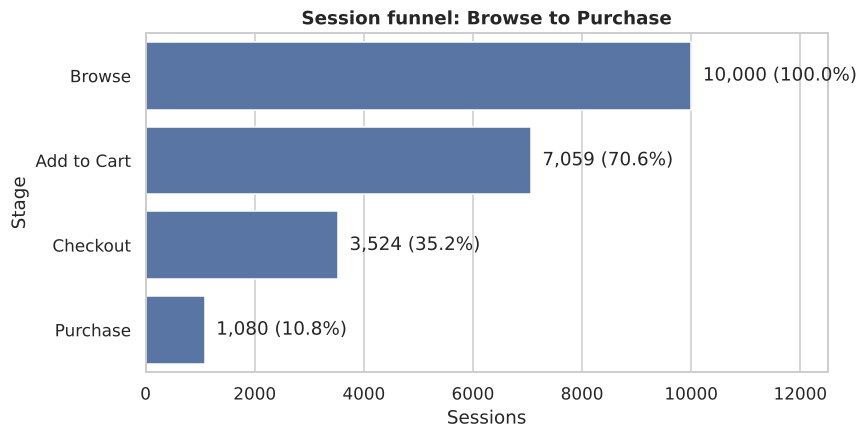

In [10]:
fig = go.Figure(go.Funnel(
    y=overall["Stage"], x=overall["Sessions"],
    textinfo="value+percent previous+percent initial",
    marker={"color": ["#4C72B0", "#55A868", "#DD8452", "#C44E52"]},
))
fig.update_layout(title="Session funnel: Browse to Purchase", margin={"l": 120})
fig.show()

try:
    fig.write_image(str(IMG_DIR / "01_funnel.png"), scale=2)   # needs: pip install kaleido
except Exception:
    fig2, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(data=overall, y="Stage", x="Sessions", ax=ax)
    for i, r in overall.iterrows():
        ax.text(r["Sessions"], i, f"  {r['Sessions']:,} ({r['Overall Conv %']:.1f}%)", va="center")
    ax.set_title("Session funnel: Browse to Purchase")
    ax.set_xlim(0, overall["Sessions"].max() * 1.25)
    save_fig("01_funnel")
    plt.close(fig2)

from IPython.display import Image
display(Image(filename=str(IMG_DIR / "01_funnel.png")))   # static copy, also renders on GitHub

## 7. Segment analysis

The same funnel is computed for every value of Device, Channel, Region and Product Category (taken from each session's first event). The question is *which step* is weak in *which segment*.

In [11]:
def segment_funnel(sess, by):
    rows = []
    for key, grp in sess.groupby(by):
        c = [int(grp[f"Reached {s}"].sum()) for s in STAGES]
        rate = lambda a, b: a / b * 100 if b else np.nan
        rows.append({
            by: key,
            "Sessions": len(grp),
            STEP_COLS[0]: rate(c[1], c[0]),
            STEP_COLS[1]: rate(c[2], c[1]),
            STEP_COLS[2]: rate(c[3], c[2]),
            "Overall %": rate(c[3], c[0]),
            "Revenue": grp["Revenue"].sum(),
            "Revenue / Session": grp["Revenue"].sum() / len(grp),
        })
    return pd.DataFrame(rows).sort_values("Overall %", ascending=False).reset_index(drop=True)

seg_tables = {d: segment_funnel(sessions, d) for d in DIMS}
for d in DIMS:
    print(f"\n=== {d} ===")
    display(seg_tables[d])


=== Device ===


,Device,Sessions,Browse → Cart %,Cart → Checkout %,Checkout → Purchase %,Overall %,Revenue,Revenue / Session
0,Desktop,3331,70.13,50.90,31.29,11.17,"399,395.43",119.90
1,Mobile,3345,70.61,48.98,31.37,10.85,"405,451.84",121.21
2,Tablet,3324,71.03,49.89,29.29,10.38,"371,558.51",111.78



=== Channel ===


,Channel,Sessions,Browse → Cart %,Cart → Checkout %,Checkout → Purchase %,Overall %,Revenue,Revenue / Session
0,Organic,2511,71.76,49.94,31.22,11.19,"307,448.35",122.44
1,Google Ads,2560,69.65,49.69,31.83,11.02,"312,769.26",122.18
2,Social Media,2440,71.07,49.65,30.55,10.78,"280,071.63",114.78
3,Email,2489,69.91,50.40,28.96,10.20,"276,116.54",110.93



=== Region ===


,Region,Sessions,Browse → Cart %,Cart → Checkout %,Checkout → Purchase %,Overall %,Revenue,Revenue / Session
0,South,2506,70.75,50.03,31.79,11.25,"311,018.57",124.11
1,East,2514,71.44,51.06,30.53,11.14,"301,767.14",120.03
2,North,2504,69.05,49.57,30.46,10.42,"288,027.95",115.03
3,West,2476,71.12,49.01,29.78,10.38,"275,592.12",111.31



=== Product_Category ===


,Product_Category,Sessions,Browse → Cart %,Cart → Checkout %,Checkout → Purchase %,Overall %,Revenue,Revenue / Session
0,Beauty,1978,71.74,50.81,31.35,11.43,"241,834.97",122.26
1,Home,1941,69.55,49.56,31.54,10.87,"232,534.83",119.80
2,Fashion,2035,70.76,50.21,30.43,10.81,"237,261.50",116.59
3,Sports,2000,70.70,52.05,29.21,10.75,"238,322.85",119.16
4,Electronics,2046,70.19,47.01,30.81,10.17,"226,451.63",110.68


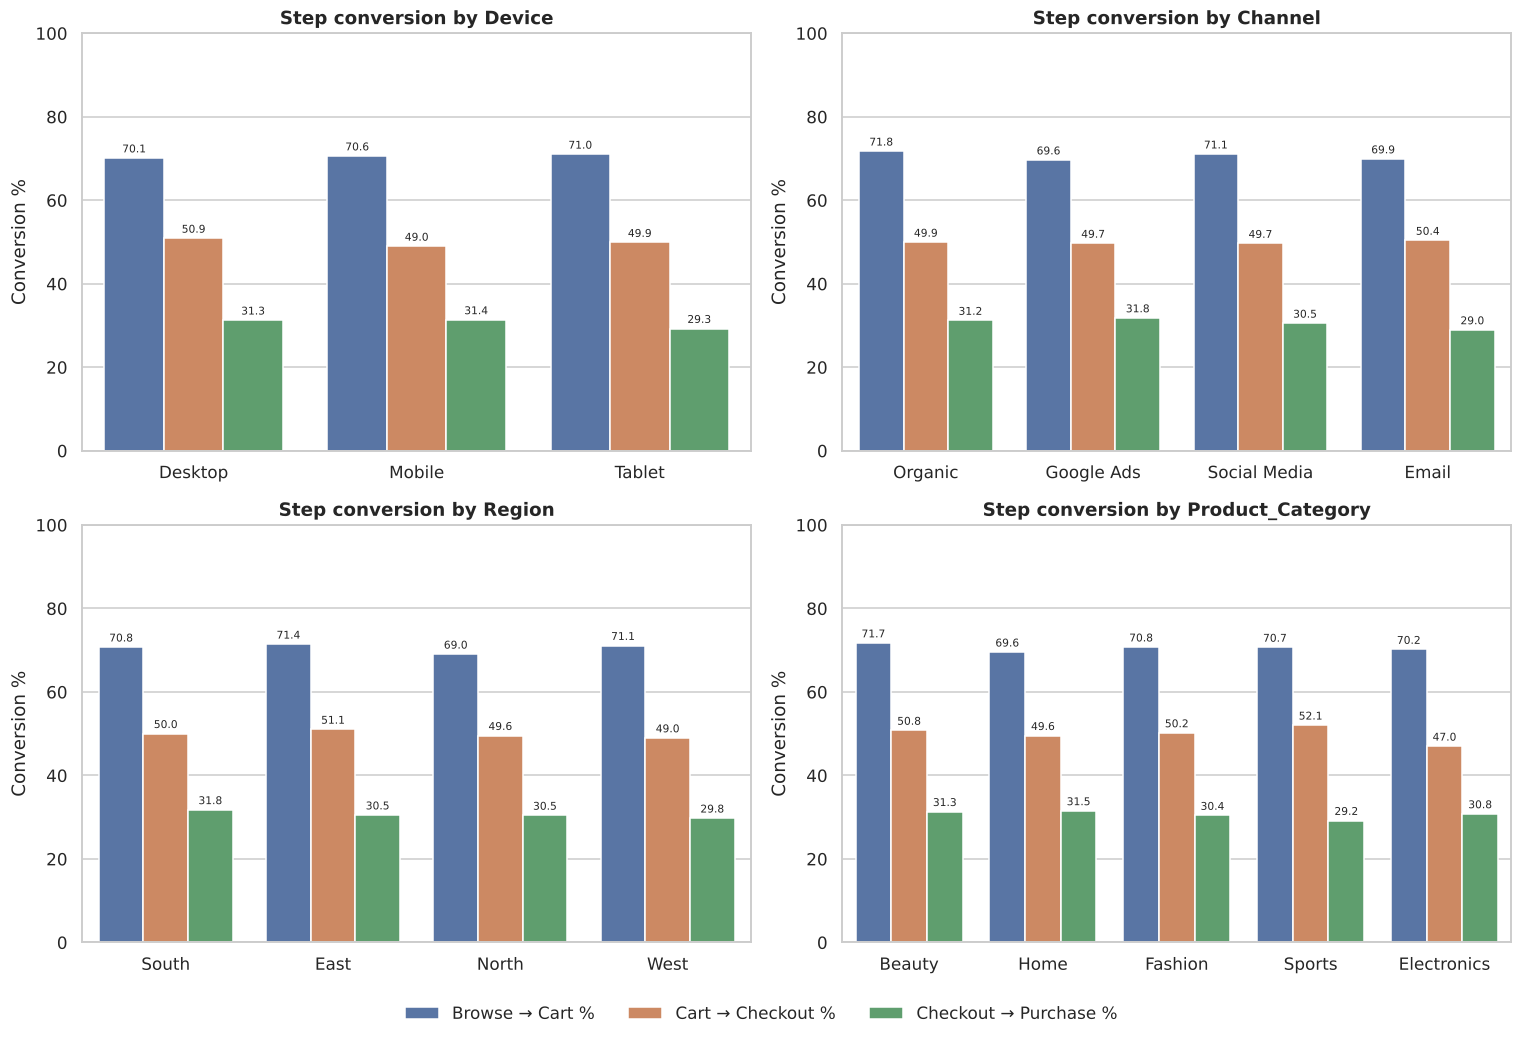

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
for ax, dim in zip(axes.ravel(), DIMS):
    t = seg_tables[dim].melt(id_vars=dim, value_vars=STEP_COLS, var_name="Step", value_name="Conversion %")
    sns.barplot(data=t, x=dim, y="Conversion %", hue="Step", ax=ax)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.1f", fontsize=7, padding=2)
    ax.set_title(f"Step conversion by {dim}")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
handles, labels = axes[0, 0].get_legend_handles_labels()
for ax in axes.ravel():
    ax.get_legend().remove()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=[0, 0.04, 1, 1])
save_fig("02_step_conversion_by_segment")
plt.show()

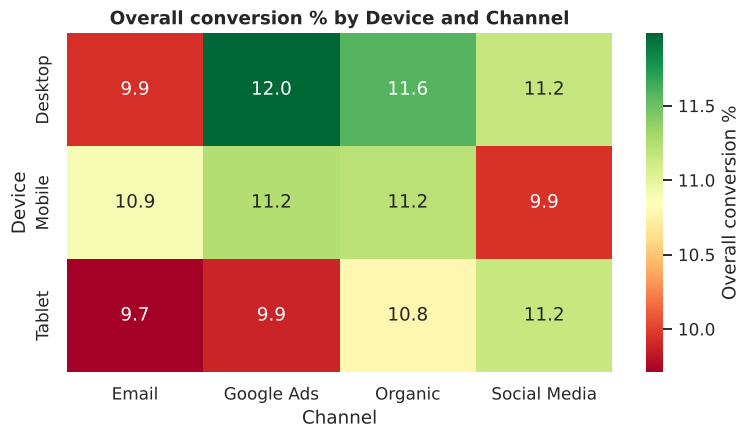

In [13]:
pivot = sessions.pivot_table(index="Device", columns="Channel", values="Purchased", aggfunc="mean") * 100
plt.figure(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="RdYlGn", cbar_kws={"label": "Overall conversion %"})
plt.title("Overall conversion % by Device and Channel")
save_fig("03_heatmap_device_channel")
plt.show()

## 8. Time analysis

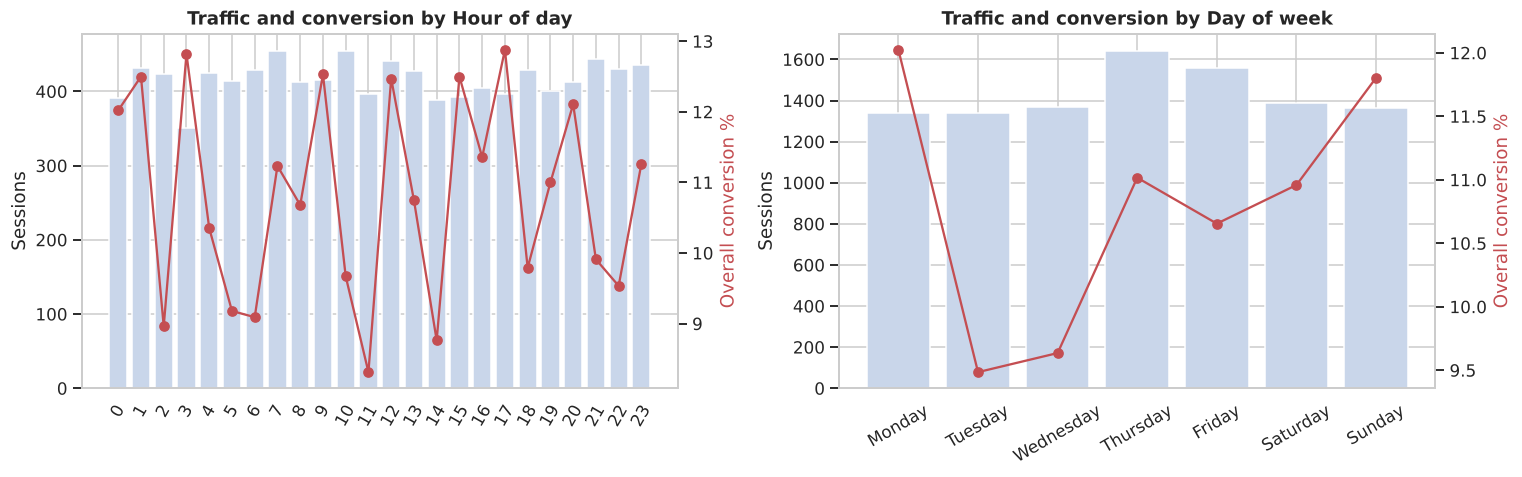

In [14]:
DOW = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

by_hour = sessions.groupby("Start_Hour").agg(Sessions=("Purchased", "size"), Conversion=("Purchased", "mean"))
by_dow = sessions.groupby("Start_DayOfWeek").agg(Sessions=("Purchased", "size"), Conversion=("Purchased", "mean")).reindex(DOW)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, tbl, title in [(axes[0], by_hour, "Hour of day"), (axes[1], by_dow, "Day of week")]:
    ax.bar(tbl.index.astype(str), tbl["Sessions"], color="#C9D6EA")
    ax.set_ylabel("Sessions")
    ax.set_title(f"Traffic and conversion by {title}")
    ax.tick_params(axis="x", rotation=60 if title == "Hour of day" else 30)
    ax2 = ax.twinx()
    ax2.plot(tbl.index.astype(str), tbl["Conversion"] * 100, color="#C44E52", marker="o")
    ax2.set_ylabel("Overall conversion %", color="#C44E52")
    ax2.grid(False)
plt.tight_layout()
save_fig("04_time_patterns")
plt.show()

,Sessions,Conversion,Revenue,Days with data,Note
Start_Week,,,,,
40,1373,12.02,"175,089.56",5,partial week
41,2320,10.39,"262,386.25",7,
42,2371,10.80,"280,997.94",7,
43,2351,11.31,"293,411.00",7,
44,1585,9.59,"164,521.03",5,partial week


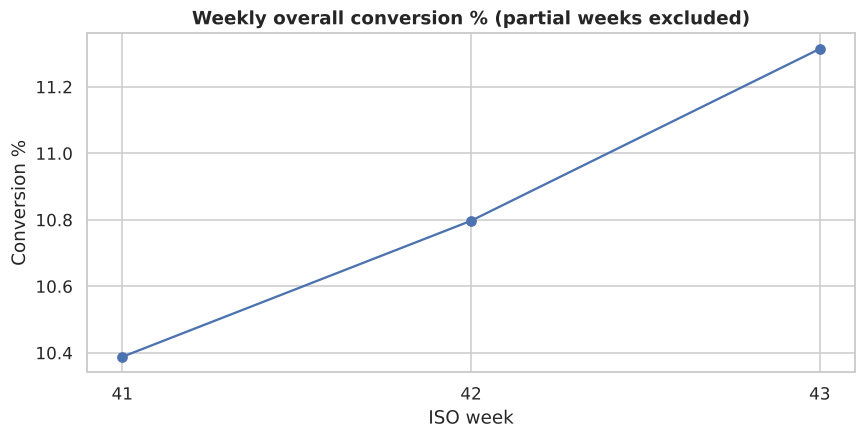

In [15]:
weekly = sessions.groupby("Start_Week").agg(Sessions=("Purchased", "size"), Conversion=("Purchased", "mean"), Revenue=("Revenue", "sum"))
weekly["Conversion"] *= 100
weekly["Days with data"] = sessions.groupby("Start_Week")["Start_Date"].nunique()
weekly["Note"] = np.where(weekly["Days with data"] < 7, "partial week", "")
display(weekly)

fig, ax = plt.subplots(figsize=(9, 4))
full = weekly[weekly["Note"] == ""]
ax.plot(full.index.astype(str), full["Conversion"], marker="o")
ax.set_title("Weekly overall conversion % (partial weeks excluded)")
ax.set_xlabel("ISO week")
ax.set_ylabel("Conversion %")
save_fig("05_weekly_trend")
plt.show()

,count,mean,median,max
Minutes between stages,,,,
Browse → Cart,"7,059.00",3.50,3.00,5.00
Cart → Checkout,"3,524.00",3.50,4.00,5.00
Checkout → Purchase,"1,080.00",3.50,4.00,5.00


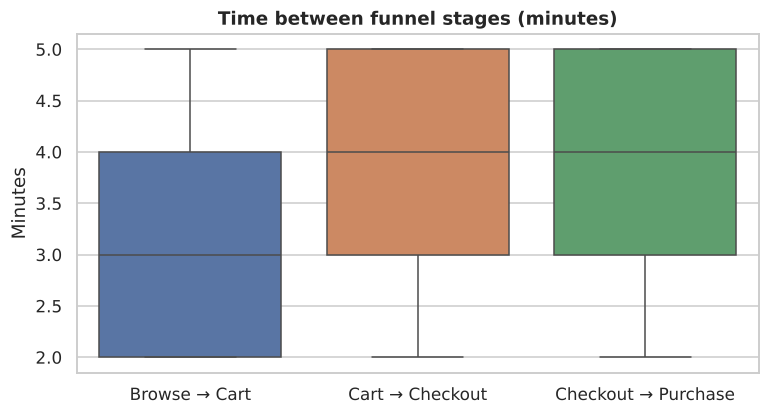

Observed gap range: 2.0 to 5.0 minutes


In [16]:
gaps = pd.DataFrame({
    "Browse → Cart": (stage_times["Add to Cart"] - stage_times["Browse"]).dt.total_seconds() / 60,
    "Cart → Checkout": (stage_times["Checkout"] - stage_times["Add to Cart"]).dt.total_seconds() / 60,
    "Checkout → Purchase": (stage_times["Purchase"] - stage_times["Checkout"]).dt.total_seconds() / 60,
}).where(lambda x: x >= 0)   # ignore the (rare) out-of-order sessions

display(gaps.describe().T[["count", "mean", "50%", "max"]].rename(columns={"50%": "median"}).round(1).rename_axis("Minutes between stages"))

plt.figure(figsize=(8, 4))
sns.boxplot(data=gaps, showfliers=False)
plt.title("Time between funnel stages (minutes)")
plt.ylabel("Minutes")
save_fig("06_time_between_stages")
plt.show()
print(f"Observed gap range: {gaps.min().min():.1f} to {gaps.max().max():.1f} minutes")

**Interpretation note.** If every gap falls in a narrow, flat range (here 1 to 5 minutes), the timestamps look generated rather than organic. In that case timing is reported for completeness but **no timing-based conclusions are drawn**, and the retargeting-delay idea is left for real data.

## 9. Statistical significance

A gap between segments only matters if it is not noise. For each dimension and each funnel step I run a **chi-square test of independence** on sessions that reached that step, with **Cramér's V** as the effect size. Because 12 tests are run, I apply a **Bonferroni correction** (α = 0.05 / 12).

In [17]:
def step_counts(sess, by, step_idx):
    prev_s, this_s = STAGES[step_idx - 1], STAGES[step_idx]
    base = sess[sess[f"Reached {prev_s}"]]
    out = base.groupby(by)[f"Reached {this_s}"].agg(n="size", x="sum")
    out["rate"] = out["x"] / out["n"]
    return out

results = []
for dim in DIMS:
    for step_idx in (1, 2, 3):
        tbl = step_counts(sessions, dim, step_idx)
        obs = np.array([tbl["x"], tbl["n"] - tbl["x"]]).T
        obs = obs[obs.sum(axis=1) > 0]
        if obs.shape[0] < 2 or (obs.sum(axis=0) == 0).any():
            continue
        chi2, p, dof, _ = stats.chi2_contingency(obs)
        v = np.sqrt(chi2 / (obs.sum() * (min(obs.shape) - 1)))
        results.append({"Dimension": dim, "Step": STEP_COLS[step_idx - 1].replace(" %", ""),
                        "Chi-square": chi2, "p-value": p, "Cramér's V": v})

sig = pd.DataFrame(results)
ALPHA = 0.05 / len(sig)
sig["Significant (Bonferroni)"] = np.where(sig["p-value"] < ALPHA, "Yes", "No")
sig["p-value"] = sig["p-value"].map(lambda p: f"{p:.4g}")
print(f"Corrected significance threshold: p < {ALPHA:.4f}")
sig

Corrected significance threshold: p < 0.0042


,Dimension,Step,Chi-square,p-value,Cramér's V,Significant (Bonferroni)
0,Device,Browse → Cart,0.65,0.7225,0.01,No
1,Device,Cart → Checkout,1.72,0.4223,0.02,No
2,Device,Checkout → Purchase,1.54,0.4625,0.02,No
3,Channel,Browse → Cart,3.59,0.3099,0.02,No
4,Channel,Cart → Checkout,0.25,0.9694,0.01,No
5,Channel,Checkout → Purchase,1.90,0.594,0.02,No
6,Region,Browse → Cart,4.11,0.2502,0.02,No
7,Region,Cart → Checkout,1.61,0.6564,0.02,No
8,Region,Checkout → Purchase,0.87,0.8319,0.02,No
9,Product_Category,Browse → Cart,2.47,0.6505,0.02,No


In [18]:
def two_prop_test(x1, n1, x2, n2):
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    p_val = 2 * (1 - stats.norm.cdf(abs(z)))
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return p1, p2, z, p_val, (p1 - p2 - 1.96 * se, p1 - p2 + 1.96 * se)

# Pick the weakest step of the funnel and compare best vs worst device at that step
steps_only = overall.iloc[1:]
leak_idx = int(steps_only["Drop-off %"].idxmax())          # index in 1..3
leak_name = f"{STAGES[leak_idx - 1]} → {STAGES[leak_idx]}"

tbl = step_counts(sessions, "Device", leak_idx).sort_values("rate")
worst, best = tbl.index[0], tbl.index[-1]
p_best, p_worst, z, p_val, ci = two_prop_test(tbl.loc[best, "x"], tbl.loc[best, "n"], tbl.loc[worst, "x"], tbl.loc[worst, "n"])

print(f"Largest leak: {leak_name} ({steps_only.loc[leak_idx, 'Drop-off %']:.1f}% drop-off)")
print(f"Best device : {best} at {p_best:.1%}")
print(f"Worst device: {worst} at {p_worst:.1%}")
print(f"Difference  : {(p_best - p_worst) * 100:.1f} percentage points "
      f"(95% CI {ci[0] * 100:.1f} to {ci[1] * 100:.1f}), z = {z:.2f}, p = {p_val:.4g}")

Largest leak: Checkout → Purchase (69.4% drop-off)
Best device : Mobile at 31.4%
Worst device: Tablet at 29.3%
Difference  : 2.1 percentage points (95% CI -1.6 to 5.8), z = 1.10, p = 0.2726


**Statistical power.** A non-significant result is only meaningful if the test could have detected a real gap. The smallest difference between two devices that this sample can detect (80% power, α = 0.05) is calculated below.

In [19]:
n_per_group = int(tbl["n"].min())
p0 = overall.loc[leak_idx, "Step Conv %"] / 100
mde = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * np.sqrt(2 * p0 * (1 - p0) / n_per_group)
print(f"Smallest device group at {leak_name}: {n_per_group:,} sessions")
print(f"Minimum detectable difference (80% power): about {mde * 100:.1f} percentage points")

Smallest device group at Checkout → Purchase: 1,157 sessions
Minimum detectable difference (80% power): about 5.4 percentage points


## 10. Revenue analysis and impact simulation

In [20]:
purchases = df[df["Event"] == "Purchase"]
aov = purchases.loc[purchases["Revenue"] > 0, "Revenue"].mean()
total_rev = sessions["Revenue"].sum()
print(f"Total revenue: {total_rev:,.0f} | Purchases: {int(sessions['Purchased'].sum()):,} | "
      f"Average order value: {aov:,.2f} | Revenue per session: {total_rev / len(sessions):,.2f}")

rev_cat = purchases.groupby("Product_Category")["Revenue"].agg(Orders="size", Revenue="sum", AOV="mean").sort_values("Revenue", ascending=False)
rev_cat["Revenue share %"] = rev_cat["Revenue"] / rev_cat["Revenue"].sum() * 100
rev_cat

Total revenue: 1,176,406 | Purchases: 1,080 | Average order value: 1,089.26 | Revenue per session: 117.64


,Orders,Revenue,AOV,Revenue share %
Product_Category,,,,
Electronics,229,"256,035.81","1,118.06",21.76
Fashion,223,"244,761.32","1,097.58",20.81
Home,212,"230,160.90","1,085.66",19.56
Sports,215,"227,888.10","1,059.94",19.37
Beauty,201,"217,559.65","1,082.39",18.49


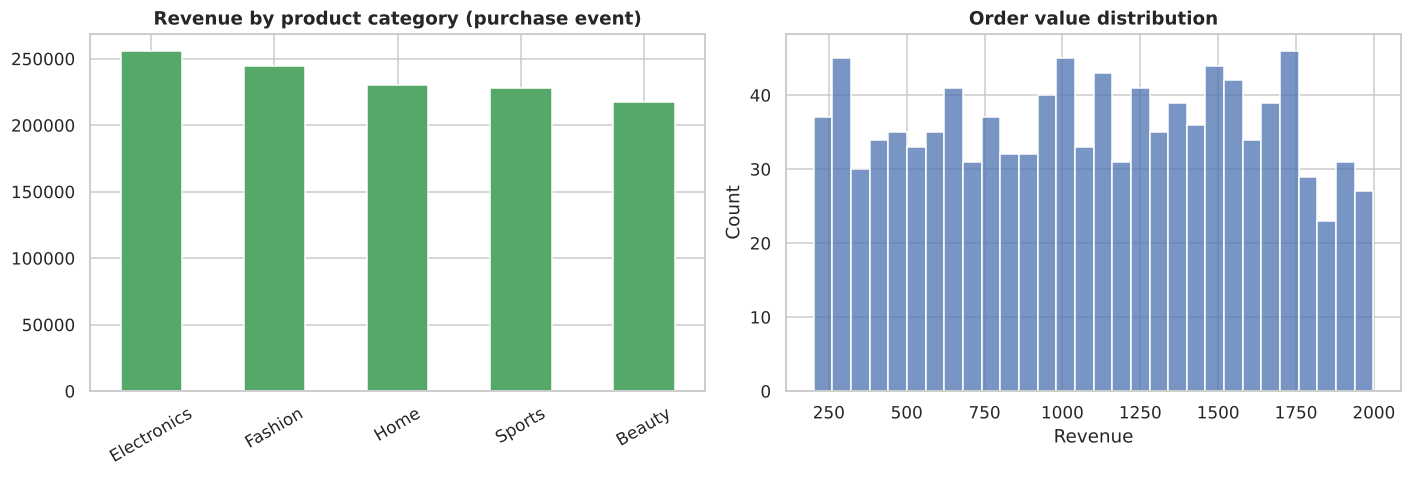

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rev_cat["Revenue"].plot.bar(ax=axes[0], color="#55A868")
axes[0].set_title("Revenue by product category (purchase event)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)
sns.histplot(purchases.loc[purchases["Revenue"] > 0, "Revenue"], bins=30, ax=axes[1])
axes[1].set_title("Order value distribution")
plt.tight_layout()
save_fig("07_revenue")
plt.show()

### Impact simulation

*If the biggest leak improved by Δ percentage points, how much extra revenue would that create?* The extra sessions that pass the leaking step continue through the later stages at today's conversion rates and are valued at the current average order value.

In [22]:
counts = overall["Sessions"].tolist()
base_sessions = counts[leak_idx - 1]                    # sessions entering the leaking step
downstream = counts[3] / counts[leak_idx]               # share of sessions at the next stage that end in purchase

scenarios = []
for delta in (1, 2, 5, 10):
    extra_next = base_sessions * delta / 100
    extra_purchases = extra_next * downstream
    scenarios.append({"Scenario": f"{leak_name} +{delta} pts",
                      "Extra purchases": extra_purchases,
                      "Extra revenue": extra_purchases * aov,
                      "Revenue uplift %": extra_purchases * aov / total_rev * 100})
scenario_df = pd.DataFrame(scenarios)
display(scenario_df)

# Device parity scenario: lift the weakest device to the best device's rate on the leaking step
gap_pts = (p_best - p_worst)
extra_parity = tbl.loc[worst, "n"] * gap_pts * downstream
print(f"\nIf {worst} matched {best} on {leak_name}: about {extra_parity:,.0f} extra purchases "
      f"and {extra_parity * aov:,.0f} extra revenue ({extra_parity * aov / total_rev:.1%} uplift).")

,Scenario,Extra purchases,Extra revenue,Revenue uplift %
0,Checkout → Purchase +1 pts,35.24,"38,385.68",3.26
1,Checkout → Purchase +2 pts,70.48,"76,771.37",6.53
2,Checkout → Purchase +5 pts,176.20,"191,928.42",16.31
3,Checkout → Purchase +10 pts,352.40,"383,856.85",32.63



If Tablet matched Mobile on Checkout → Purchase: about 25 extra purchases and 26,783 extra revenue (2.3% uplift).


## 11. Bounce analysis

A bounce means the visitor left after a single interaction, so a session flagged as bounced that went on to Checkout or Purchase is contradictory. I compare the provided `Bounce_Flag` with a behavioural definition (**single-event session**) before deciding which one to rely on.

In [23]:
sessions["Single_Event"] = sessions["Events"] == 1
print("Provided Bounce_Flag vs deepest stage reached (row %):")
display((pd.crosstab(sessions["Bounce_Flag"], sessions["Deepest_Stage"], normalize="index")[STAGES] * 100).round(1))

print("\nSessions flagged as bounce:", f"{sessions['Bounced'].mean():.1%}",
      "| single-event sessions:", f"{sessions['Single_Event'].mean():.1%}")
agree = (sessions["Bounced"] == sessions["Single_Event"]).mean()
print(f"Agreement between the flag and the behavioural definition: {agree:.1%}")

flag_is_not_purchase = (sessions["Bounced"] == ~sessions["Purchased"]).mean()
print(f"Bounce_Flag = Yes exactly when the session did NOT purchase in {flag_is_not_purchase:.1%} of sessions")

Provided Bounce_Flag vs deepest stage reached (row %):


Deepest_Stage,Browse,Add to Cart,Checkout,Purchase
Bounce_Flag,,,,
No,0.00,0.00,0.00,100.00
Yes,33.00,39.60,27.40,0.00



Sessions flagged as bounce: 89.2% | single-event sessions: 29.4%
Agreement between the flag and the behavioural definition: 40.2%
Bounce_Flag = Yes exactly when the session did NOT purchase in 100.0% of sessions


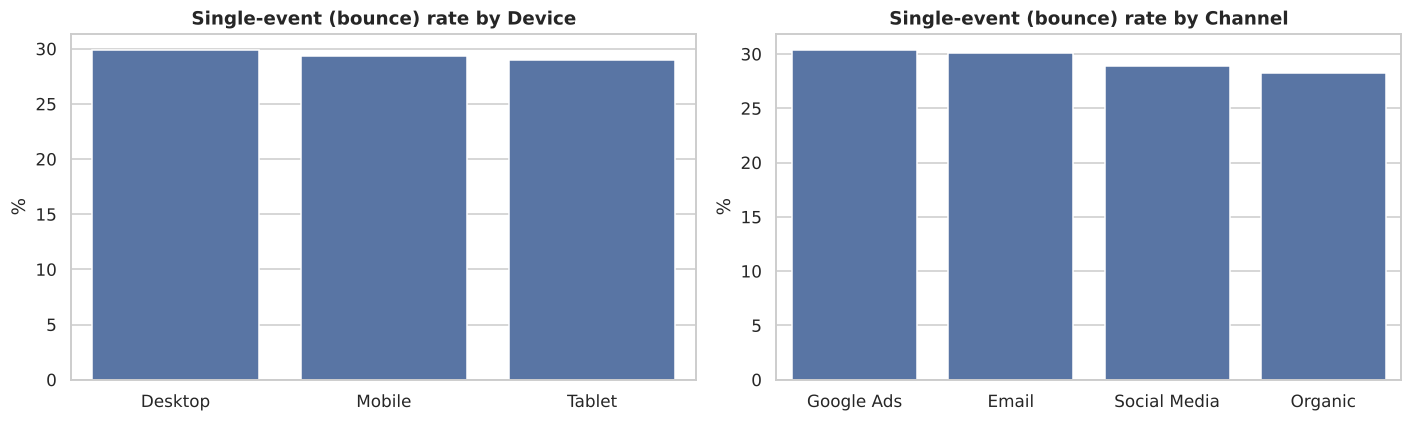

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, dim in zip(axes, ["Device", "Channel"]):
    rate = sessions.groupby(dim)["Single_Event"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.set_title(f"Single-event (bounce) rate by {dim}")
    ax.set_ylabel("%")
    ax.set_xlabel("")
plt.tight_layout()
save_fig("08_bounce")
plt.show()

**Finding.** If `Bounce_Flag` matches "did not purchase" in (almost) every session, it is not a bounce flag at all. It is a non-conversion flag, and using it as a bounce rate would be misleading. Bounce analysis here therefore uses the **single-event session** definition instead.

## 12. Executive summary (auto-generated)

In [25]:
top = seg_tables["Channel"]
best_ch, worst_ch = top.iloc[0], top.iloc[-1]
sig_hits = sig[sig["Significant (Bonferroni)"] == "Yes"][["Dimension", "Step"]].apply(lambda r: f"{r['Dimension']} ({r['Step']})", axis=1).tolist()
channel_sig = bool((sig["Dimension"].eq("Channel") & sig["Significant (Bonferroni)"].eq("Yes")).any())
attr_changed = sess_attr_changes["Device"].mean()
bounce_deep = int((sessions["Bounced"] & (sessions["Max_Stage_Idx"] >= 2)).sum())
d5 = scenario_df.loc[scenario_df["Scenario"].str.contains("\\+5 pts"), "Extra revenue"].iloc[0]

summary = f'''
EXECUTIVE SUMMARY
-----------------
1. Scope: {len(sessions):,} sessions, {df['Date'].min():%d %b %Y} to {df['Date'].max():%d %b %Y}. Overall conversion (Browse to Purchase): {overall['Overall Conv %'].iloc[-1]:.1f}%.
2. Biggest leak: {leak_name}, where {steps_only.loc[leak_idx, 'Drop-off %']:.1f}% of sessions drop out ({int(steps_only.loc[leak_idx, 'Sessions Lost']):,} sessions).
3. Device gap at that step: {best} converts at {p_best:.1%} vs {worst} at {p_worst:.1%} (difference {(p_best - p_worst) * 100:.1f} pts, p = {p_val:.3g}, {'significant' if p_val < 0.05 else 'not significant'}). With about {n_per_group:,} sessions per device, only gaps of roughly {mde * 100:.1f} pts or more could be detected reliably.
4. Channels: {best_ch['Channel']} has the highest overall conversion ({best_ch['Overall %']:.1f}%), {worst_ch['Channel']} the lowest ({worst_ch['Overall %']:.1f}%). Channel differences {'are' if channel_sig else 'are not'} statistically significant at any funnel step.
5. Statistically significant segment effects after Bonferroni correction: {', '.join(sig_hits) if sig_hits else 'none'}. {'No segment effect is detectable at this sample size, so the leak looks funnel-wide rather than segment-specific.' if not sig_hits else ''}
6. Revenue: total {total_rev:,.0f}, average order value {aov:,.2f}. A 5 point improvement at {leak_name} is worth about {d5:,.0f} in extra revenue ({d5 / total_rev:.1%}).
7. Data caveats: {attr_changed:.0%} of sessions change device between events (first-event attributes are used), and Bounce_Flag equals "did not purchase" in {flag_is_not_purchase:.1%} of sessions, so it is not a genuine bounce metric (sections 3, 5, 11).
'''
print(summary)
(OUT_DIR / "executive_summary.txt").write_text(summary)


EXECUTIVE SUMMARY
-----------------
1. Scope: 10,000 sessions, 01 Oct 2025 to 31 Oct 2025. Overall conversion (Browse to Purchase): 10.8%.
2. Biggest leak: Checkout → Purchase, where 69.4% of sessions drop out (2,444 sessions).
3. Device gap at that step: Mobile converts at 31.4% vs Tablet at 29.3% (difference 2.1 pts, p = 0.273, not significant). With about 1,157 sessions per device, only gaps of roughly 5.4 pts or more could be detected reliably.
4. Channels: Organic has the highest overall conversion (11.2%), Email the lowest (10.2%). Channel differences are not statistically significant at any funnel step.
5. Statistically significant segment effects after Bonferroni correction: none. No segment effect is detectable at this sample size, so the leak looks funnel-wide rather than segment-specific.
6. Revenue: total 1,176,406, average order value 1,089.26. A 5 point improvement at Checkout → Purchase is worth about 191,928 in extra revenue (16.3%).
7. Data caveats: 56% of sessions ch

1185

**Recommendations** (based on the run on this dataset)
1. **Focus on Checkout → Purchase**, the largest leak (about 69% of sessions that reach checkout do not buy). Since no segment differs significantly, the fix should be funnel-wide: shorter checkout, guest checkout, more payment options, upfront shipping costs. Validate with an A/B test.
2. **Recover Cart → Checkout drop-off** (about 50% lost) with cart-abandonment reminders.
3. **Do not reallocate budget by device, channel or region on this evidence.** Differences are within noise at this sample size. The lowest Cart → Checkout rate (Electronics) is a hypothesis to test on more data, not a conclusion.
4. **Fix tracking:** `Bounce_Flag` currently mirrors non-purchase, and device/channel/region change inside single sessions. Add a genuine bounce metric and stable session attributes before the next analysis cycle.

## 13. Export for BI tools (Power BI / Tableau)

In [26]:
overall.to_csv(OUT_DIR / "funnel_overall.csv", index=False)
for d in DIMS:
    seg_tables[d].to_csv(OUT_DIR / f"funnel_by_{d.lower()}.csv", index=False)
sessions.reset_index().to_csv(OUT_DIR / "sessions_clean.csv", index=False)
sig.to_csv(OUT_DIR / "significance_tests.csv", index=False)
scenario_df.to_csv(OUT_DIR / "impact_scenarios.csv", index=False)
print("Saved:", sorted(p.name for p in OUT_DIR.iterdir()))

Saved: ['executive_summary.txt', 'funnel_by_channel.csv', 'funnel_by_device.csv', 'funnel_by_product_category.csv', 'funnel_by_region.csv', 'funnel_overall.csv', 'impact_scenarios.csv', 'sessions_clean.csv', 'significance_tests.csv']


## 14. Limitations and next steps

**Limitations**
- Each user appears to have a single session, so repeat purchase, retention and cohort analysis are not possible.
- Session attributes change inside sessions, which is not realistic. First-event attributes are used as an assumption.
- Observational data only: segment differences show association, not causation. An A/B test is needed to prove that a change improves conversion.
- The last week of data may be partial.

**Next steps**
- Reproduce the funnel in SQL (see `funnel_analysis.sql`) and reconcile the numbers with this notebook.
- Build a Power BI or Tableau dashboard from the CSVs in `outputs/`.
- Validate the approach on a real dataset such as the REES46 e-commerce behaviour dataset.